# COS802 Project — Housing Price Prediction
## Notebook 04: Model Comparison

This notebook addresses **RQ3** by comparing the approved regression models under a consistent development-only evaluation:

- Ordinary Linear Regression — unregularized linear baseline from Notebook 03
- Ridge Regression — regularized linear baseline
- Random Forest — bagging-based nonlinear model
- XGBoost — boosting-based nonlinear model

The naive mean-price predictor from Notebook 03 is retained as the minimum benchmark. Both **original** and **domain-engineered** feature representations are considered. Hyperparameters for Ridge, Random Forest and XGBoost are selected using only the frozen five development folds. Linear Regression is not tuned; its frozen Notebook 03 cross-validation results are incorporated directly. The **586-property held-out test set remains locked** for Notebook 05.

### Primary selection metric
**RMSE** is used as the primary model-selection metric because large housing-price errors are especially costly. MAE and R² remain important secondary metrics. Notebook 03 showed that target transformation can trade lower typical error for unstable large errors, so the cross-family comparison below uses the **raw SalePrice target**.


In [15]:
from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from xgboost import XGBRegressor
except ImportError:
    !pip -q install xgboost
    from xgboost import XGBRegressor


# Canonical reusable project code
PROJECT_DIR = Path("/content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import SEED, TARGET, IDENTIFIERS, DATA_FILE, PROCESSED_DIR, SPLITS_DIR, FIGURES_DIR
from src.features import (
    STRUCTURAL_NONE_COLS, ENGINEERED_FEATURES, apply_structural_absence,
    AmesFeatureEngineer, validate_engineered_features, validate_feature_alignment,
)
from src.preprocessing import ORDINAL_CATEGORY_MAP, build_preprocessor
from src.evaluation import regression_metrics

SEED = 16153970
np.random.seed(SEED)

PROJECT_DIR = Path("/content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT")
RAW_DIR = PROJECT_DIR/"data"/"raw"
PROCESSED_DIR = PROJECT_DIR/"data"/"processed"
SPLITS_DIR = PROJECT_DIR/"data"/"splits"
FIGURES_DIR = PROJECT_DIR/"figures"

df = pd.read_csv(RAW_DIR/"AmesHousing.txt", sep="\t")
split_membership = pd.read_csv(SPLITS_DIR/"train_test_split.csv")
cv_membership = pd.read_csv(SPLITS_DIR/"development_cv_folds.csv")

print("Dataset:", df.shape)


Dataset: (2930, 82)


## 1. Restore the frozen development split


In [17]:
TARGET="SalePrice"
IDENTIFIERS=["Order","PID"]

dev_idx = split_membership.loc[
    split_membership["split"]=="development","row_index"
].astype(int).to_numpy()
test_idx = split_membership.loc[
    split_membership["split"]=="test","row_index"
].astype(int).to_numpy()

dev_df = df.loc[dev_idx].copy()
X_dev_raw = dev_df.drop(columns=[TARGET]+IDENTIFIERS)
y_dev = dev_df[TARGET].astype(float).copy()

print("Development:", X_dev_raw.shape)
print("Locked test rows:", len(test_idx))


Development: (2344, 79)
Locked test rows: 586


## 2. Reuse the Notebook 02 feature definitions


In [18]:
X_dev_engineered = AmesFeatureEngineer().fit_transform(X_dev_raw)
validate_engineered_features(X_dev_engineered)
print("Using canonical feature engineering from src.features")


Using canonical feature engineering from src.features


In [19]:
# Preprocessing is implemented centrally in src/preprocessing.py.
print("Using canonical build_preprocessor from src.preprocessing")


Using canonical build_preprocessor from src.preprocessing


## 3. Restore the same five development folds


In [20]:
row_to_pos={int(idx):pos for pos,idx in enumerate(dev_idx)}
folds=[]
for f in sorted(cv_membership["fold"].unique()):
    z=cv_membership[cv_membership["fold"]==f]
    tr=np.array([row_to_pos[int(r)] for r in z.loc[z.role=="train","row_index"]])
    va=np.array([row_to_pos[int(r)] for r in z.loc[z.role=="validation","row_index"]])
    folds.append((tr,va))
    print(f"Fold {f}: train={len(tr)}, validation={len(va)}")


Fold 1: train=1875, validation=469
Fold 2: train=1875, validation=469
Fold 3: train=1875, validation=469
Fold 4: train=1875, validation=469
Fold 5: train=1876, validation=468


## 4. Evaluation helpers

Every configuration is evaluated on exactly the same validation observations. Preprocessing is refitted inside each training fold.

For this model-family comparison we use the **raw SalePrice target**. Notebook 03 showed that the log target reduced MAE but could substantially worsen RMSE on expensive/extreme observations. The raw target therefore gives a clearer like-for-like comparison for the primary RMSE criterion. The log-target Ridge results remain documented in Notebook 03.


In [21]:
def evaluate_config(X, model_factory, scale_numeric, label, params):
    rows=[]
    for fold,(tr,va) in enumerate(folds,1):
        pipe=Pipeline([
            ("preprocessor",build_preprocessor(X.iloc[tr],scale_numeric)),
            ("model",model_factory(params))
        ])
        start=time.time()
        pipe.fit(X.iloc[tr],y_dev.iloc[tr])
        pred=np.maximum(pipe.predict(X.iloc[va]),0)
        elapsed=time.time()-start
        rows.append({
            "Configuration":label,
            "Fold":fold,
            "FitSeconds":elapsed,
            **regression_metrics(y_dev.iloc[va],pred)
        })
    return pd.DataFrame(rows)


## 5. Compact development-only hyperparameter search

The grids are deliberately small. The purpose is to compare model families fairly without turning the project into an exhaustive optimization exercise.

- **Ridge:** a small regularization search.
- **Random Forest:** tree count, depth and minimum leaf size.
- **XGBoost:** depth, learning rate, tree count and regularization/subsampling choices.

No held-out test observation participates in this search.


In [22]:
def ridge_factory(p):
    return Ridge(alpha=p["alpha"])

def rf_factory(p):
    return RandomForestRegressor(
        n_estimators=p["n_estimators"],
        max_depth=p["max_depth"],
        min_samples_leaf=p["min_samples_leaf"],
        max_features=p["max_features"],
        random_state=SEED,
        n_jobs=-1
    )

def xgb_factory(p):
    return XGBRegressor(
        n_estimators=p["n_estimators"],
        max_depth=p["max_depth"],
        learning_rate=p["learning_rate"],
        subsample=p["subsample"],
        colsample_bytree=p["colsample_bytree"],
        reg_lambda=p["reg_lambda"],
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=SEED,
        n_jobs=-1
    )

RIDGE_GRID=[
    {"alpha":0.1},{"alpha":1.0},{"alpha":10.0},{"alpha":100.0}
]

RF_GRID=[
    {"n_estimators":400,"max_depth":None,"min_samples_leaf":1,"max_features":1.0},
    {"n_estimators":400,"max_depth":None,"min_samples_leaf":2,"max_features":1.0},
    {"n_estimators":400,"max_depth":20,"min_samples_leaf":1,"max_features":0.7},
    {"n_estimators":400,"max_depth":20,"min_samples_leaf":2,"max_features":0.7}
]

XGB_GRID=[
    {"n_estimators":500,"max_depth":3,"learning_rate":0.03,"subsample":0.8,"colsample_bytree":0.8,"reg_lambda":1.0},
    {"n_estimators":500,"max_depth":3,"learning_rate":0.05,"subsample":0.8,"colsample_bytree":0.8,"reg_lambda":1.0},
    {"n_estimators":400,"max_depth":4,"learning_rate":0.03,"subsample":0.8,"colsample_bytree":0.8,"reg_lambda":1.0},
    {"n_estimators":400,"max_depth":4,"learning_rate":0.05,"subsample":0.9,"colsample_bytree":0.9,"reg_lambda":5.0}
]

print("Configurations per representation:",
      len(RIDGE_GRID)+len(RF_GRID)+len(XGB_GRID))


Configurations per representation: 12


## 6. Run all model-family comparisons

This cell can take several minutes because each configuration is refitted across five folds.


In [23]:
search_rows=[]

X_original = X_dev_raw.copy() # Define X_original using the raw development data

representations={
    "Original":X_original,
    "Engineered":X_dev_engineered
}

families=[
    ("Ridge",RIDGE_GRID,ridge_factory,True),
    ("Random Forest",RF_GRID,rf_factory,False),
    ("XGBoost",XGB_GRID,xgb_factory,False)
]

for rep_name,X in representations.items():
    for family,grid,factory,scale in families:
        for i,params in enumerate(grid,1):
            label=f"{family} | {rep_name} | Config {i}"
            print("Running:",label)
            fold_df=evaluate_config(X,factory,scale,label,params)
            fold_df["Model"]=family
            fold_df["Representation"]=rep_name
            fold_df["Config"]=i
            fold_df["Params"]=str(params)
            search_rows.append(fold_df)

search_results=pd.concat(search_rows,ignore_index=True)
print("Completed rows:",len(search_results))

Running: Ridge | Original | Config 1
Running: Ridge | Original | Config 2
Running: Ridge | Original | Config 3
Running: Ridge | Original | Config 4
Running: Random Forest | Original | Config 1
Running: Random Forest | Original | Config 2
Running: Random Forest | Original | Config 3
Running: Random Forest | Original | Config 4
Running: XGBoost | Original | Config 1
Running: XGBoost | Original | Config 2
Running: XGBoost | Original | Config 3
Running: XGBoost | Original | Config 4
Running: Ridge | Engineered | Config 1
Running: Ridge | Engineered | Config 2
Running: Ridge | Engineered | Config 3
Running: Ridge | Engineered | Config 4
Running: Random Forest | Engineered | Config 1
Running: Random Forest | Engineered | Config 2
Running: Random Forest | Engineered | Config 3
Running: Random Forest | Engineered | Config 4
Running: XGBoost | Engineered | Config 1
Running: XGBoost | Engineered | Config 2
Running: XGBoost | Engineered | Config 3
Running: XGBoost | Engineered | Config 4
Complete

## 7. Summarize hyperparameter search


In [24]:
search_summary=(
    search_results.groupby(
        ["Model","Representation","Config","Params"],as_index=False
    ).agg(
        MAE_mean=("MAE","mean"),
        MAE_sd=("MAE","std"),
        RMSE_mean=("RMSE","mean"),
        RMSE_sd=("RMSE","std"),
        R2_mean=("R2","mean"),
        R2_sd=("R2","std"),
        FitSeconds_mean=("FitSeconds","mean")
    )
)

search_summary=search_summary.sort_values("RMSE_mean")
display(search_summary.round(3))

search_results.to_csv(PROCESSED_DIR/"model_comparison_cv_fold_results.csv",index=False)
search_summary.to_csv(PROCESSED_DIR/"model_comparison_search_summary.csv",index=False)


,Model,Representation,Config,Params,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd,FitSeconds_mean
19,XGBoost,Engineered,4,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13516.278,1230.580,22195.446,3521.745,0.922,0.017,0.583
18,XGBoost,Engineered,3,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13462.610,1170.501,22228.793,3296.460,0.921,0.017,0.595
22,XGBoost,Original,3,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13879.612,1015.472,22636.490,2739.515,0.918,0.015,0.531
23,XGBoost,Original,4,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13948.709,987.662,22807.604,2515.801,0.917,0.013,0.567
17,XGBoost,Engineered,2,"{'n_estimators': 500, 'max_depth': 3, 'learnin...",13491.411,966.218,23036.087,3019.365,0.915,0.016,0.549
21,XGBoost,Original,2,"{'n_estimators': 500, 'max_depth': 3, 'learnin...",13687.534,773.512,23092.588,2590.595,0.915,0.015,0.512
20,XGBoost,Original,1,"{'n_estimators': 500, 'max_depth': 3, 'learnin...",13923.136,836.839,23180.586,2736.833,0.914,0.017,0.491
16,XGBoost,Engineered,1,"{'n_estimators': 500, 'max_depth': 3, 'learnin...",13672.094,1037.125,23255.441,3287.551,0.914,0.017,0.567
2,Random Forest,Engineered,3,"{'n_estimators': 400, 'max_depth': 20, 'min_sa...",15100.606,774.841,25231.605,2518.589,0.898,0.015,2.491
3,Random Forest,Engineered,4,"{'n_estimators': 400, 'max_depth': 20, 'min_sa...",15123.335,830.098,25300.715,2600.989,0.898,0.015,1.950


## 8. Select one configuration per tuned model family and incorporate Notebook 03 baselines
For Ridge, Random Forest and XGBoost, the lowest-RMSE configuration is selected separately for each feature representation. Ordinary Linear Regression and the naive mean predictor are not tuned; their frozen five-fold results are loaded from Notebook 03. Only **raw-target** Linear/Ridge results are used in the cross-family RQ3 comparison because the log-target experiments showed unstable large-error behaviour.


In [25]:
# Select best tuned configuration for Ridge, Random Forest and XGBoost.
selected_tuned=(
    search_summary.sort_values("RMSE_mean")
    .groupby(["Model","Representation"],as_index=False)
    .first()
    .sort_values("RMSE_mean")
)

# Load the frozen Notebook 03 baseline summary.
baseline_summary = pd.read_csv(PROCESSED_DIR/"baseline_cv_summary.csv")

def baseline_row(experiment, model, representation):
    r = baseline_summary.loc[baseline_summary["Experiment"] == experiment]
    if len(r) != 1:
        raise ValueError(f"Expected exactly one Notebook 03 row for {experiment!r}; found {len(r)}.")
    r = r.iloc[0]
    return {
        "Model": model,
        "Representation": representation,
        "Config": 0,
        "Params": "No tuning (Notebook 03 fixed baseline)",
        "MAE_mean": r["MAE_mean"],
        "MAE_sd": r["MAE_sd"],
        "RMSE_mean": r["RMSE_mean"],
        "RMSE_sd": r["RMSE_sd"],
        "R2_mean": r["R2_mean"],
        "R2_sd": r["R2_sd"],
        "FitSeconds_mean": np.nan,
    }

fixed_rows = pd.DataFrame([
    baseline_row("Linear | Original | Raw", "Linear Regression", "Original"),
    baseline_row("Linear | Engineered | Raw", "Linear Regression", "Engineered"),
])

selected = pd.concat([selected_tuned, fixed_rows], ignore_index=True)
selected = selected.sort_values("RMSE_mean").reset_index(drop=True)

display(selected.round(3))
selected.to_csv(PROCESSED_DIR/"selected_model_configs.csv",index=False)


,Model,Representation,Config,Params,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd,FitSeconds_mean
0,XGBoost,Engineered,4,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13516.278,1230.580,22195.446,3521.745,0.922,0.017,0.583
1,XGBoost,Original,3,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13879.612,1015.472,22636.490,2739.515,0.918,0.015,0.531
2,Random Forest,Engineered,3,"{'n_estimators': 400, 'max_depth': 20, 'min_sa...",15100.606,774.841,25231.605,2518.589,0.898,0.015,2.491
3,Random Forest,Original,3,"{'n_estimators': 400, 'max_depth': 20, 'min_sa...",15472.121,849.929,25908.861,2399.048,0.893,0.015,2.149
4,Ridge,Original,3,{'alpha': 10.0},17495.185,677.543,29938.109,5114.661,0.854,0.049,0.073
5,Ridge,Engineered,3,{'alpha': 10.0},16910.022,796.778,30634.014,6310.082,0.845,0.064,0.132
6,Linear Regression,Original,0,No tuning (Notebook 03 fixed baseline),17461.926,437.767,30676.663,6233.560,0.845,0.064,NaN
7,Linear Regression,Engineered,0,No tuning (Notebook 03 fixed baseline),16390.240,806.091,32093.542,10572.962,0.820,0.119,NaN


## 9. Compare all approved model families and feature representations
This table is the main RQ3 development comparison. It places the fixed ordinary Linear Regression baseline beside the tuned Ridge, Random Forest and XGBoost results using the same development observations, five folds and raw target.


In [26]:
comparison=selected[[
    "Model","Representation","Config","Params",
    "MAE_mean","MAE_sd","RMSE_mean","RMSE_sd","R2_mean","R2_sd"
]].copy()

model_order=["Linear Regression","Ridge","Random Forest","XGBoost"]
comparison["Model"]=pd.Categorical(comparison["Model"],categories=model_order,ordered=True)
comparison=comparison.sort_values(["RMSE_mean","Model"]).reset_index(drop=True)

display(comparison.round(3))
comparison.to_csv(PROCESSED_DIR/"approved_model_family_comparison.csv",index=False)


,Model,Representation,Config,Params,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd
0,XGBoost,Engineered,4,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13516.278,1230.580,22195.446,3521.745,0.922,0.017
1,XGBoost,Original,3,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13879.612,1015.472,22636.490,2739.515,0.918,0.015
2,Random Forest,Engineered,3,"{'n_estimators': 400, 'max_depth': 20, 'min_sa...",15100.606,774.841,25231.605,2518.589,0.898,0.015
3,Random Forest,Original,3,"{'n_estimators': 400, 'max_depth': 20, 'min_sa...",15472.121,849.929,25908.861,2399.048,0.893,0.015
4,Ridge,Original,3,{'alpha': 10.0},17495.185,677.543,29938.109,5114.661,0.854,0.049
5,Ridge,Engineered,3,{'alpha': 10.0},16910.022,796.778,30634.014,6310.082,0.845,0.064
6,Linear Regression,Original,0,No tuning (Notebook 03 fixed baseline),17461.926,437.767,30676.663,6233.560,0.845,0.064
7,Linear Regression,Engineered,0,No tuning (Notebook 03 fixed baseline),16390.240,806.091,32093.542,10572.962,0.820,0.119


## 10. Controlled feature-engineering effect by model family
Original and engineered representations are compared within each approved model family. Positive MAE/RMSE reduction indicates lower error after feature engineering; positive ΔR² indicates improved explained variance.


In [27]:
effects=[]
for model in comparison["Model"].unique():
    o=comparison[(comparison.Model==model)&(comparison.Representation=="Original")].iloc[0]
    e=comparison[(comparison.Model==model)&(comparison.Representation=="Engineered")].iloc[0]
    effects.append({
        "Model":model,
        "MAE_reduction_%":100*(o.MAE_mean-e.MAE_mean)/o.MAE_mean,
        "RMSE_reduction_%":100*(o.RMSE_mean-e.RMSE_mean)/o.RMSE_mean,
        "Delta_R2":e.R2_mean-o.R2_mean
    })

effects=pd.DataFrame(effects)
display(effects.round(4))
effects.to_csv(PROCESSED_DIR/"feature_engineering_effect_by_model.csv",index=False)


,Model,MAE_reduction_%,RMSE_reduction_%,Delta_R2
0,XGBoost,2.6178,1.9484,0.0036
1,Random Forest,2.4012,2.6140,0.0056
2,Ridge,3.3447,-2.3245,-0.0088
3,Linear Regression,6.1373,-4.6187,-0.0254


## 11. Visual comparison


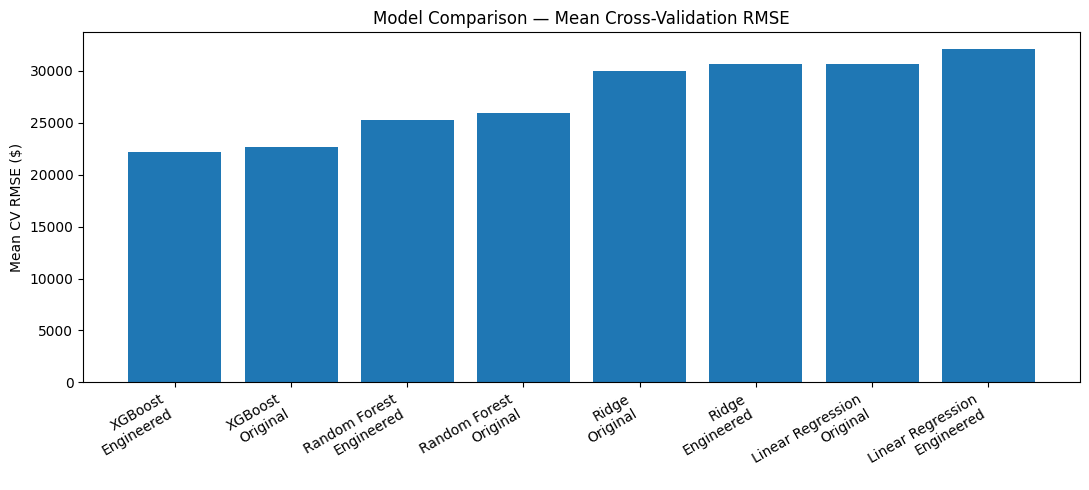

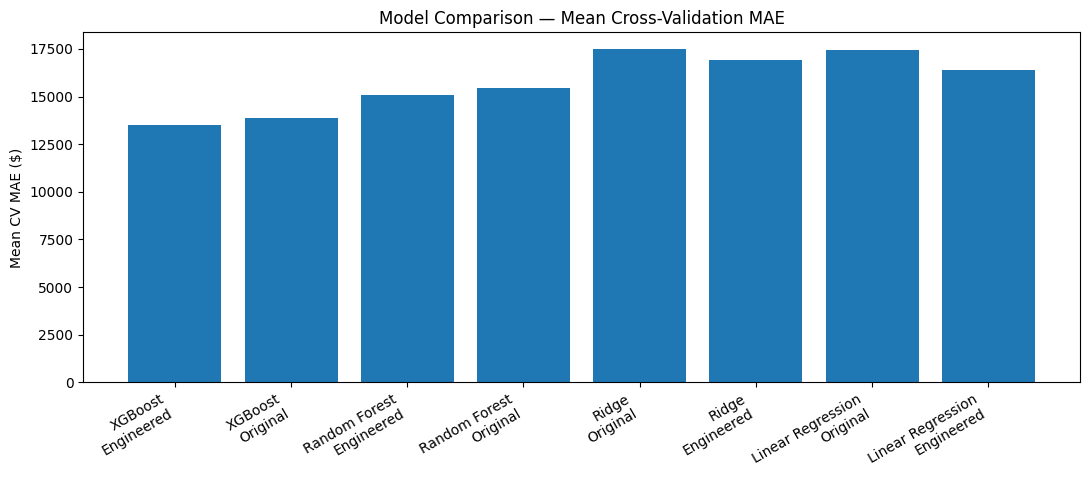

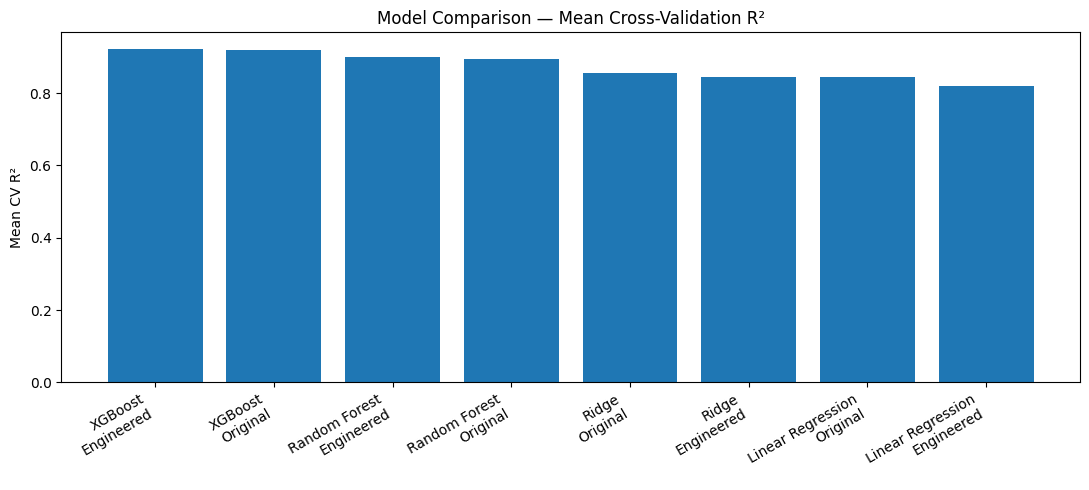

In [29]:
# Visual comparison of the approved model families
plot_df = comparison.copy()

# Model is stored as a pandas Categorical, so convert it to string
# before combining it with the feature-representation label.
plot_df["Label"] = (
    plot_df["Model"].astype(str)
    + "\n"
    + plot_df["Representation"].astype(str)
)

# RMSE comparison
plt.figure(figsize=(11, 5))
plt.bar(plot_df["Label"], plot_df["RMSE_mean"])
plt.ylabel("Mean CV RMSE ($)")
plt.title("Model Comparison — Mean Cross-Validation RMSE")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "model_comparison_rmse.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# MAE comparison
plt.figure(figsize=(11, 5))
plt.bar(plot_df["Label"], plot_df["MAE_mean"])
plt.ylabel("Mean CV MAE ($)")
plt.title("Model Comparison — Mean Cross-Validation MAE")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "model_comparison_mae.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# R² comparison
plt.figure(figsize=(11, 5))
plt.bar(plot_df["Label"], plot_df["R2_mean"])
plt.ylabel("Mean CV R²")
plt.title("Model Comparison — Mean Cross-Validation R²")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "model_comparison_r2.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 12. Evidence summary and configuration for Notebook 05
The development winner is selected by mean CV RMSE from the approved cross-family comparison. The naive mean benchmark is also loaded from Notebook 03 for context, but it is not eligible for final model selection.


In [30]:
selected_for_final=comparison.sort_values("RMSE_mean").iloc[0]

baseline_summary = pd.read_csv(PROCESSED_DIR/"baseline_cv_summary.csv")
mean_row = baseline_summary.loc[baseline_summary["Experiment"]=="Naive mean"].iloc[0]

print("Minimum benchmark from Notebook 03")
print("----------------------------------")
print(f'Mean predictor CV MAE: ${mean_row["MAE_mean"]:,.2f}')
print(f'Mean predictor CV RMSE: ${mean_row["RMSE_mean"]:,.2f}')
print(f'Mean predictor CV R²: {mean_row["R2_mean"]:.4f}')

print("\nDevelopment-selected configuration")
print("----------------------------------")
print("Model:",selected_for_final["Model"])
print("Representation:",selected_for_final["Representation"])
print("Config:",int(selected_for_final["Config"]))
print("Parameters:",selected_for_final["Params"])
print(f'Mean CV MAE: ${selected_for_final["MAE_mean"]:,.2f}')
print(f'Mean CV RMSE: ${selected_for_final["RMSE_mean"]:,.2f}')
print(f'Mean CV R²: {selected_for_final["R2_mean"]:.4f}')

pd.DataFrame([selected_for_final]).to_csv(
    PROCESSED_DIR/"development_selected_configuration.csv",index=False
)


Minimum benchmark from Notebook 03
----------------------------------
Mean predictor CV MAE: $58,314.69
Mean predictor CV RMSE: $79,591.79
Mean predictor CV R²: -0.0027

Development-selected configuration
----------------------------------
Model: XGBoost
Representation: Engineered
Config: 4
Parameters: {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 5.0}
Mean CV MAE: $13,516.28
Mean CV RMSE: $22,195.45
Mean CV R²: 0.9217


## Notebook 04 Conclusions

Use the executed results to make the empirical RQ3 comparison; do not decide the conclusion before execution.

This notebook:
- compares the approved **Linear Regression, Ridge Regression, Random Forest and XGBoost** model families;
- retains the naive mean-price predictor as the minimum benchmark;
- uses the same development observations and five frozen folds for all cross-model evidence;
- uses the **raw SalePrice target** for the cross-family comparison after Notebook 03 showed instability in some log-target folds;
- compares original and engineered representations;
- tunes Ridge, Random Forest and XGBoost only on development data while treating Linear Regression as an untuned baseline;
- uses RMSE as the predefined primary selection metric while retaining MAE and R²;
- saves the selected development configuration for final evaluation.

The **held-out 586-property test set remains untouched**.

### Next notebook
`05_interpretability_error_analysis.ipynb` refits the development-selected configuration on the complete development set, evaluates it **once** on the locked test set, performs residual/error analysis, and uses feature importance/SHAP to address RQ4.
